<a href="https://colab.research.google.com/github/SohanKumar56/23102A0056_RPROGRAMMING/blob/main/Lab8_23102A0056_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Sohan Kumar

Roll no.: 23102A0056

Branch: CMPN A

**Installing and loading packages**

In [ ]:
packages <- c("data.table", "arrow", "ggplot2", "dplyr",
              "lubridate", "foreach", "doParallel",
              "microbenchmark", "purrr")

install.packages(setdiff(packages, rownames(installed.packages())),
                 repos = "https://cloud.r-project.org")

invisible(lapply(packages, library, character.only = TRUE))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘assertthat’, ‘iterators’



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%



Attaching package: ‘arrow’


The following object is masked from ‘package:utils’:

    timestamp



Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘lubridate’


The following object is masked from ‘package:arrow’:

    duration


The following objects are masked from ‘package:data.table’:

    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


Loading requ

**Importing dataset**

In [ ]:
trip_url <- "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
zone_url <- "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

download.file(trip_url, "taxi.parquet", mode = "wb")
download.file(zone_url, "zones.csv", mode = "wb")

cols <- c("tpep_pickup_datetime", "tpep_dropoff_datetime",
          "passenger_count", "trip_distance", "PULocationID",
          "DOLocationID", "payment_type", "fare_amount",
          "tip_amount", "total_amount")

taxi <- as.data.table(
  arrow::read_parquet("taxi.parquet", col_select = all_of(cols))
)

zones <- fread("zones.csv")

cat("Rows:", nrow(taxi), "\nColumns:", ncol(taxi))

Rows: 2964624 
Columns: 10

**Inspecting and cleaning data**

In [ ]:
str(taxi)
summary(taxi)

taxi <- unique(taxi)

taxi <- taxi[
  !is.na(tpep_pickup_datetime) &
  !is.na(tpep_dropoff_datetime) &
  !is.na(trip_distance) &
  !is.na(fare_amount) &
  !is.na(total_amount) &
  trip_distance > 0 &
  fare_amount >= 0 &
  total_amount >= 0
]

cat("Rows after cleaning:", nrow(taxi))

Classes ‘data.table’ and 'data.frame':	2964624 obs. of  10 variables:
 $ tpep_pickup_datetime : POSIXct, format: "2024-01-01 00:57:55" "2024-01-01 00:03:00" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2024-01-01 01:17:43" "2024-01-01 00:09:36" ...
 $ passenger_count      : int  1 1 1 1 1 1 2 0 1 1 ...
 $ trip_distance        : num  1.72 1.8 4.7 1.4 0.8 ...
 $ PULocationID         : int  186 140 236 79 211 148 138 246 161 113 ...
 $ DOLocationID         : int  79 236 79 211 148 141 181 231 261 113 ...
 $ payment_type         : int  2 1 1 1 1 1 1 2 2 2 ...
 $ fare_amount          : num  17.7 10 23.3 10 7.9 29.6 45.7 25.4 31 3 ...
 $ tip_amount           : num  0 3.75 3 2 3.2 6.9 10 0 0 0 ...
 $ total_amount         : num  22.7 18.8 31.3 17 16.1 ...
 - attr(*, ".internal.selfref")=<pointer: 0x58bef85c13f0> 


 tpep_pickup_datetime          tpep_dropoff_datetime         passenger_count 
 Min.   :2002-12-31 22:59:39   Min.   :2002-12-31 23:05:41   Min.   :0.000   
 1st Qu.:2024-01-09 15:59:19   1st Qu.:2024-01-09 16:16:23   1st Qu.:1.000   
 Median :2024-01-17 10:45:37   Median :2024-01-17 11:03:51   Median :1.000   
 Mean   :2024-01-17 00:46:36   Mean   :2024-01-17 01:02:13   Mean   :1.339   
 3rd Qu.:2024-01-24 18:23:52   3rd Qu.:2024-01-24 18:40:29   3rd Qu.:1.000   
 Max.   :2024-02-01 00:01:15   Max.   :2024-02-02 13:56:52   Max.   :9.000   
                                                             NAs    :140162  
 trip_distance        PULocationID  DOLocationID    payment_type  
 Min.   :0.000e+00   Min.   :  1   Min.   :  1.0   Min.   :0.000  
 1st Qu.:1.000e+00   1st Qu.:132   1st Qu.:114.0   1st Qu.:1.000  
 Median :1.680e+00   Median :162   Median :162.0   Median :1.000  
 Mean   :3.652e+00   Mean   :166   Mean   :165.1   Mean   :1.161  
 3rd Qu.:3.110e+00   3rd Qu.:234   3rd Qu

Rows after cleaning: 2870108

**Feature engineering and zone joining**

In [ ]:
taxi[, `:=`(
  hour = hour(tpep_pickup_datetime),
  day = day(tpep_pickup_datetime),
  weekday = wday(tpep_pickup_datetime, label = TRUE),
  month = month(tpep_pickup_datetime, label = TRUE)
)]

pickup_zones <- copy(zones)
setnames(pickup_zones,
         c("LocationID", "Borough", "Zone"),
         c("PULocationID", "PickupBorough", "PickupZone"))

drop_zones <- copy(zones)
setnames(drop_zones,
         c("LocationID", "Borough", "Zone"),
         c("DOLocationID", "DropBorough", "DropZone"))

taxi <- merge(taxi, pickup_zones, by = "PULocationID",
              all.x = TRUE, sort = FALSE)

taxi <- merge(taxi, drop_zones, by = "DOLocationID",
              all.x = TRUE, sort = FALSE)

head(taxi)

DOLocationID,PULocationID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,fare_amount,tip_amount,total_amount,hour,day,weekday,month,PickupBorough,PickupZone,service_zone.x,DropBorough,DropZone,service_zone.y
<int>,<int>,<dttm>,<dttm>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<ord>,<ord>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
79,186,2024-01-01 00:57:55,2024-01-01 01:17:43,1,1.72,2,17.7,0.00,22.70,0,1,Mon,Jan,Manhattan,Penn Station/Madison Sq West,Yellow Zone,Manhattan,East Village,Yellow Zone
236,140,2024-01-01 00:03:00,2024-01-01 00:09:36,1,1.80,1,10.0,3.75,18.75,0,1,Mon,Jan,Manhattan,Lenox Hill East,Yellow Zone,Manhattan,Upper East Side North,Yellow Zone
79,236,2024-01-01 00:17:06,2024-01-01 00:35:01,1,4.70,1,23.3,3.00,31.30,0,1,Mon,Jan,Manhattan,Upper East Side North,Yellow Zone,Manhattan,East Village,Yellow Zone
211,79,2024-01-01 00:36:38,2024-01-01 00:44:56,1,1.40,1,10.0,2.00,17.00,0,1,Mon,Jan,Manhattan,East Village,Yellow Zone,Manhattan,SoHo,Yellow Zone
148,211,2024-01-01 00:46:51,2024-01-01 00:52:57,1,0.80,1,7.9,3.20,16.10,0,1,Mon,Jan,Manhattan,SoHo,Yellow Zone,Manhattan,Lower East Side,Yellow Zone
141,148,2024-01-01 00:54:08,2024-01-01 01:26:31,1,4.70,1,29.6,6.90,41.50,0,1,Mon,Jan,Manhattan,Lower East Side,Yellow Zone,Manhattan,Lenox Hill West,Yellow Zone


**Trips by hour, weekday, and month**

In [ ]:
hourly <- taxi[, .(Trips = .N), by = hour][order(hour)]

daily <- taxi[, .(Trips = .N), by = weekday]

monthly <- taxi[, .(Trips = .N), by = month]

print(hourly)
print(daily)
print(monthly)

     hour  Trips
    <int>  <int>
 1:     0  75252
 2:     1  50488
 3:     2  34974
 4:     3  22949
 5:     4  15286
 6:     5  17497
 7:     6  39416
 8:     7  80872
 9:     8 113506
10:     9 125622
11:    10 135430
12:    11 146754
13:    12 159918
14:    13 165360
15:    14 178032
16:    15 184007
17:    16 184974
18:    17 200311
19:    18 206287
20:    19 178810
21:    20 155560
22:    21 155917
23:    22 138245
24:    23 104641
     hour  Trips
    <int>  <int>
   weekday  Trips
     <ord>  <int>
1:     Mon 393317
2:     Sun 326751
3:     Thu 416289
4:     Tue 449182
5:     Wed 480870
6:     Fri 396435
7:     Sat 407264
   month   Trips
   <ord>   <int>
1:   Jan 2870094
2:   Dec      11
3:   Feb       3


**Fare, revenue, and distance analysis**

In [ ]:
fare_summary <- taxi[, .(
  TotalTrips = .N,
  AverageFare = mean(fare_amount),
  AverageDistance = mean(trip_distance),
  TotalRevenue = sum(total_amount),
  AverageRevenue = mean(total_amount)
)]

print(fare_summary)

distance_fare <- taxi[, .(
  AverageFare = mean(fare_amount),
  Trips = .N
), by = .(DistanceGroup = cut(
  trip_distance,
  breaks = c(0, 2, 5, 10, Inf),
  labels = c("0-2", "2-5", "5-10", "10+"),
  include.lowest = TRUE
))]

print(distance_fare)

   TotalTrips AverageFare AverageDistance TotalRevenue AverageRevenue
        <int>       <num>           <num>        <num>          <num>
1:    2870108    18.49675        3.733159     78483671        27.3452
   DistanceGroup AverageFare   Trips
          <fctr>       <num>   <int>
1:           0-2    9.967235 1663750
2:           2-5   18.761314  750593
3:           10+   64.729344  225112
4:          5-10   34.039123  230653


**Top routes and payment methods**

In [ ]:
top_routes <- taxi[, .(
  Trips = .N,
  Revenue = sum(total_amount)
), by = .(PickupZone, DropZone)][
  order(-Trips)][1:10]

revenue_routes <- taxi[, .(
  Revenue = sum(total_amount),
  Trips = .N
), by = .(PickupZone, DropZone)][
  order(-Revenue)][1:10]

payments <- taxi[, .(Trips = .N),
                 by = .(PickupBorough, payment_type)][
  order(-Trips)]

print(top_routes)
print(revenue_routes)
print(payments)

               PickupZone              DropZone Trips  Revenue
                   <char>                <char> <int>    <num>
 1: Upper East Side South Upper East Side North 21642 340615.5
 2: Upper East Side North Upper East Side South 19199 308728.5
 3: Upper East Side North Upper East Side North 15199 200811.1
 4: Upper East Side South Upper East Side South 14118 195140.5
 5:        Midtown Center Upper East Side South 10139 172958.6
 6:   Lincoln Square East Upper West Side South  8828 132207.8
 7: Upper East Side South        Midtown Center  8718 143645.7
 8:        Midtown Center Upper East Side North  8664 189614.7
 9: Upper West Side South   Lincoln Square East  8544 124589.8
10: Upper West Side South Upper West Side North  8306 114916.2
                   PickupZone                  DropZone  Revenue Trips
                       <char>                    <char>    <num> <int>
 1:               JFK Airport            Outside of NYC 719586.8  5832
 2:               JFK Airport T

**Functional programming using lapply()**

In [ ]:
parts <- split(taxi, taxi$hour)

functional_result <- lapply(parts, function(x) {
  data.table(
    Hour = x$hour[1],
    Trips = nrow(x),
    Revenue = sum(x$total_amount)
  )
})

functional_result <- rbindlist(functional_result)
print(functional_result)

     Hour  Trips   Revenue
    <int>  <int>     <num>
 1:     0  75252 2150524.0
 2:     1  50488 1307760.1
 3:     2  34974  860289.4
 4:     3  22949  612928.3
 5:     4  15286  496231.1
 6:     5  17497  657085.1
 7:     6  39416 1188536.4
 8:     7  80872 2147078.8
 9:     8 113506 2899100.2
10:     9 125622 3253781.4
11:    10 135430 3529353.2
12:    11 146754 3738237.1
13:    12 159918 4114577.9
14:    13 165360 4382783.3
15:    14 178032 4924574.0
16:    15 184007 5042460.7
17:    16 184974 5504289.7
18:    17 200311 5639800.6
19:    18 206287 5538720.2
20:    19 178810 4947617.5
21:    20 155560 4245075.8
22:    21 155917 4282040.8
23:    22 138245 3924005.9
24:    23 104641 3096819.3
     Hour  Trips   Revenue
    <int>  <int>     <num>


**Vectorized implementation**

In [ ]:
vectorized_result <- data.table(
  Hour = 0:23,
  Trips = as.integer(tabulate(taxi$hour + 1, nbins = 24))
)

print(vectorized_result)

     Hour  Trips
    <int>  <int>
 1:     0  75252
 2:     1  50488
 3:     2  34974
 4:     3  22949
 5:     4  15286
 6:     5  17497
 7:     6  39416
 8:     7  80872
 9:     8 113506
10:     9 125622
11:    10 135430
12:    11 146754
13:    12 159918
14:    13 165360
15:    14 178032
16:    15 184007
17:    16 184974
18:    17 200311
19:    18 206287
20:    19 178810
21:    20 155560
22:    21 155917
23:    22 138245
24:    23 104641
     Hour  Trips
    <int>  <int>


**data.table implementation**

In [ ]:
dt_result <- taxi[, .(
  Trips = .N,
  Revenue = sum(total_amount)
), by = hour][order(hour)]

print(dt_result)

     hour  Trips   Revenue
    <int>  <int>     <num>
 1:     0  75252 2150523.9
 2:     1  50488 1307760.1
 3:     2  34974  860289.4
 4:     3  22949  612928.3
 5:     4  15286  496231.1
 6:     5  17497  657085.1
 7:     6  39416 1188536.4
 8:     7  80872 2147078.8
 9:     8 113506 2899100.2
10:     9 125622 3253781.4
11:    10 135430 3529353.2
12:    11 146754 3738237.1
13:    12 159918 4114577.9
14:    13 165360 4382783.3
15:    14 178032 4924573.9
16:    15 184007 5042460.7
17:    16 184974 5504289.7
18:    17 200311 5639800.6
19:    18 206287 5538720.2
20:    19 178810 4947617.5
21:    20 155560 4245075.8
22:    21 155917 4282040.8
23:    22 138245 3924005.9
24:    23 104641 3096819.3
     hour  Trips   Revenue
    <int>  <int>     <num>


**Benchmark the three approaches**

In [ ]:
benchmark_data <- taxi[, .(hour, total_amount)]

functional_fun <- function() {
  lapply(split(benchmark_data, benchmark_data$hour),
         function(x) nrow(x))
}

vectorized_fun <- function() {
  tabulate(benchmark_data$hour + 1, nbins = 24)
}

datatable_fun <- function() {
  benchmark_data[, .N, by = hour]
}

bench <- microbenchmark(
  Functional = functional_fun(),
  Vectorized = vectorized_fun(),
  DataTable = datatable_fun(),
  times = 5
)

print(bench)

Unit: milliseconds
       expr       min        lq      mean    median        uq       max neval
 Functional 87.936032 89.468805 103.17804 104.32755 108.30268 125.85512     5
 Vectorized  9.580783  9.621333  12.68779  10.21637  14.43064  19.58980     5
  DataTable 44.698008 45.500739  47.82735  46.61150  50.20979  52.11673     5


**Sequential processing**

In [ ]:
chunks <- split(
  seq_len(nrow(taxi)),
  cut(seq_len(nrow(taxi)), breaks = 4, labels = FALSE)
)

sequential_time <- system.time({
  sequential_result <- lapply(chunks, function(i) {
    taxi[i, .(
      Trips = .N,
      Revenue = sum(total_amount)
    )]
  })
})

sequential_result <- rbindlist(sequential_result)

print(sequential_result)
print(sequential_time)

    Trips  Revenue
    <int>    <num>
1: 717527 20189449
2: 717527 19812290
3: 717527 19269156
4: 717527 19212776
   user  system elapsed 
  0.034   0.000   0.036 


**Parallel processing using foreach and doParallel**

In [ ]:
cores <- max(1, min(2, parallel::detectCores() - 1))

cl <- parallel::makeCluster(cores)
registerDoParallel(cl)

parallel_time <- system.time({
  parallel_result <- foreach(
    i = chunks,
    .combine = rbind,
    .packages = "data.table"
  ) %dopar% {
    taxi[i, .(
      Trips = .N,
      Revenue = sum(total_amount)
    )]
  }
})

stopCluster(cl)
registerDoSEQ()

print(parallel_result)
print(parallel_time)

    Trips  Revenue
    <int>    <num>
1: 717527 20189449
2: 717527 19812290
3: 717527 19269156
4: 717527 19212776
   user  system elapsed 
  2.119   0.249   3.929 


**Speedup and visualizations**

Sequential time: 0.036 seconds
Parallel time: 3.929 seconds
Speedup: 0.01 x


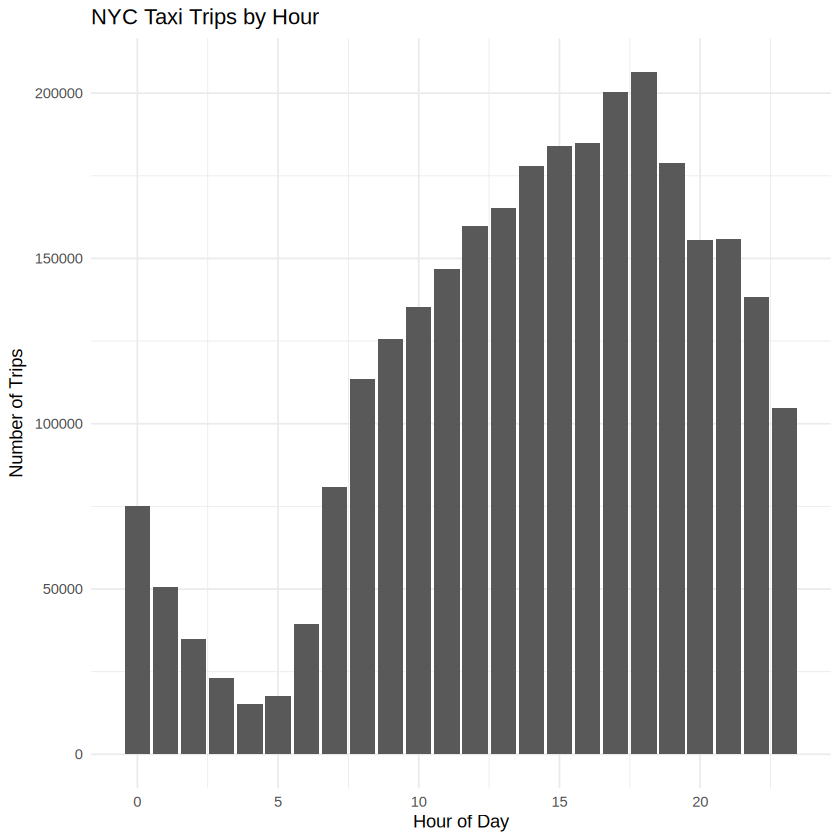

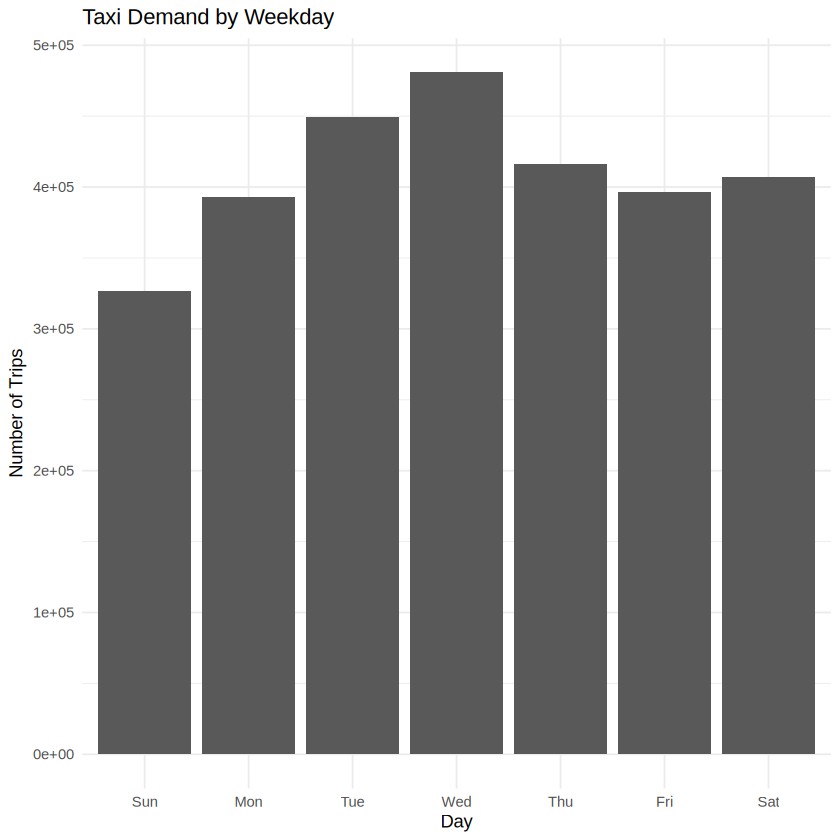

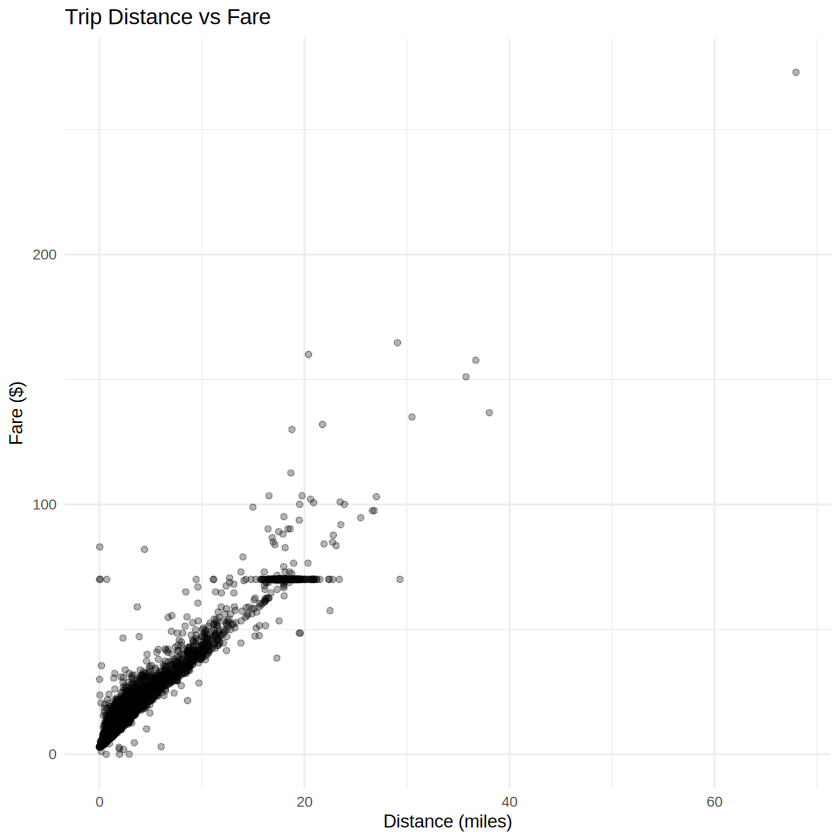

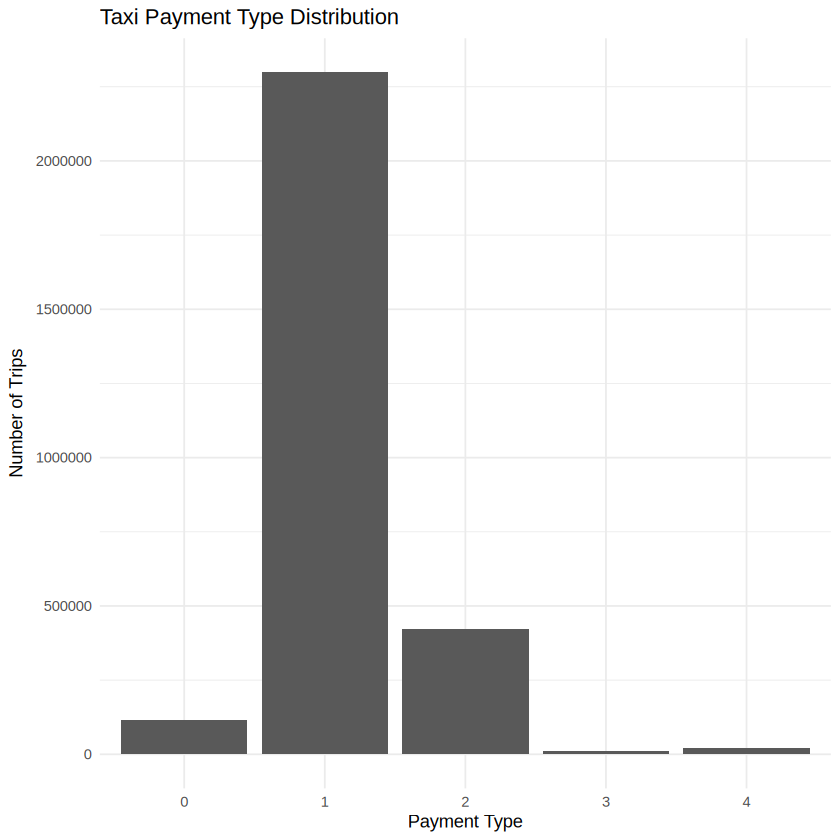

In [ ]:
speedup <- sequential_time["elapsed"] /
           parallel_time["elapsed"]

cat("Sequential time:",
    sequential_time["elapsed"], "seconds\n")

cat("Parallel time:",
    parallel_time["elapsed"], "seconds\n")

cat("Speedup:", round(speedup, 2), "x\n")

ggplot(hourly, aes(x = hour, y = Trips)) +
  geom_col() +
  labs(title = "NYC Taxi Trips by Hour",
       x = "Hour of Day", y = "Number of Trips") +
  theme_minimal()

ggplot(daily, aes(x = weekday, y = Trips)) +
  geom_col() +
  labs(title = "Taxi Demand by Weekday",
       x = "Day", y = "Number of Trips") +
  theme_minimal()

ggplot(taxi[sample(.N, min(.N, 5000))],
       aes(x = trip_distance, y = fare_amount)) +
  geom_point(alpha = 0.3) +
  labs(title = "Trip Distance vs Fare",
       x = "Distance (miles)", y = "Fare ($)") +
  theme_minimal()

ggplot(taxi, aes(x = factor(payment_type))) +
  geom_bar() +
  labs(title = "Taxi Payment Type Distribution",
       x = "Payment Type", y = "Number of Trips") +
  theme_minimal()

**Observations, critical analysis, and conclusion**

In [ ]:
cat("OBSERVATIONS\n")

cat("1. Taxi demand varies across hours and weekdays.\n")
cat("2. Fare generally increases with trip distance.\n")
cat("3. data.table provides concise grouping and aggregation.\n")
cat("4. Vectorized operations avoid explicit R-level loops.\n")
cat("5. Parallel processing may reduce execution time, but has overhead.\n\n")

cat("PERFORMANCE ANALYSIS\n")
print(bench)

cat("\nSequential time:",
    sequential_time["elapsed"], "seconds")

cat("\nParallel time:",
    parallel_time["elapsed"], "seconds")

cat("\nSpeedup:", round(speedup, 2), "x\n")

cat("\nCONCLUSION\n")
cat("The NYC Taxi dataset was analyzed using R. ",
    "Functional, vectorized, and data.table approaches ",
    "were compared through benchmarking. Sequential and ",
    "parallel execution were evaluated using foreach and ",
    "doParallel. data.table is suitable for efficient ",
    "large-scale data manipulation, while parallel ",
    "processing is useful when its overhead is justified.\n")

OBSERVATIONS
1. Taxi demand varies across hours and weekdays.
2. Fare generally increases with trip distance.
3. data.table provides concise grouping and aggregation.
4. Vectorized operations avoid explicit R-level loops.
5. Parallel processing may reduce execution time, but has overhead.

PERFORMANCE ANALYSIS
Unit: milliseconds
       expr       min        lq      mean    median        uq       max neval
 Functional 87.936032 89.468805 103.17804 104.32755 108.30268 125.85512     5
 Vectorized  9.580783  9.621333  12.68779  10.21637  14.43064  19.58980     5
  DataTable 44.698008 45.500739  47.82735  46.61150  50.20979  52.11673     5

Sequential time: 0.036 seconds
Parallel time: 3.929 seconds
Speedup: 0.01 x

CONCLUSION
The NYC Taxi dataset was analyzed using R.  Functional, vectorized, and data.table approaches  were compared through benchmarking. Sequential and  parallel execution were evaluated using foreach and  doParallel. data.table is suitable for efficient  large-scale data m